### Iowa fatal crash data statistics and visualization

- Reads Iowa crash data for a given year (or a range of years) from 2014 to 2024 into a pandas dataframe
- Does summary statistics on some columns and plots them
- visualizes the data on a map

## Data

 The 43 fields below are the ones present in **every** year, so they are safe to use when combining years. They hold numeric codes only

**Identification**

| Field | Meaning |
|---|---|
| `STATE` | State FIPS code (always 19 = Iowa) |
| `ST_CASE` | Case number for the crash, unique within a year (190001, 190002, ...) |
| `YEAR` | Crash year (2014-2024) |

**When**

| Field | Meaning |
|---|---|
| `MONTH`, `DAY`, `DAY_WEEK` | Month, day of month, day of week (1 = Sunday) |
| `HOUR`, `MINUTE` | Time of the crash (24-hour clock; 99 = unknown) |
| `NOT_HOUR`, `NOT_MIN` | Time EMS was notified |
| `ARR_HOUR`, `ARR_MIN` | Time EMS arrived at the scene |
| `HOSP_HR`, `HOSP_MN` | Time EMS arrived at the hospital |

**Where**

| Field | Meaning |
|---|---|
| `LATITUDE`, `LONGITUD` | Crash location in decimal degrees (note the spelling `LONGITUD`) |
| `COUNTY` | County code |
| `CITY` | City code (0 = not in a city) |
| `TWAY_ID`, `TWAY_ID2` | Name or number of the trafficway; `TWAY_ID2` is the second road at an intersection and is often empty |
| `ROUTE` | Route signing (interstate, US highway, state, county, ...) |
| `NHS` | 1 if the road is on the National Highway System |
| `MILEPT` | Milepoint along the route |
| `SP_JUR` | Special jurisdiction (e.g. military or park land) |
| `RAIL` | Railroad grade crossing ID (`0000000` = none) |

**Crash circumstances**

| Field | Meaning |
|---|---|
| `HARM_EV` | First harmful event (collision with a vehicle, tree, pedestrian, rollover, ...) |
| `MAN_COLL` | Manner of collision (front-to-rear, angle, ...) |
| `TYP_INT` | Type of intersection |
| `REL_ROAD` | Where the first harmful event happened relative to the road (on roadway, shoulder, median, ...) |
| `RELJCT1`, `RELJCT2` | Whether the crash was in an interchange area, and its location relative to a junction |
| `WEATHER` | Atmospheric conditions (clear, rain, snow, fog, ...) |
| `LGT_COND` | Light condition (daylight, dark, dusk, ...) |
| `WRK_ZONE` | Work zone type (0 = not in a work zone) |
| `SCH_BUS` | 1 if a school-bus-related vehicle was involved |

**People and vehicles**

| Field | Meaning |
|---|---|
| `FATALS` | Number of people killed |
| `PERSONS` | Total people involved |
| `PERMVIT` | People in motor vehicles in transport |
| `PERNOTMVIT` | People not in motor vehicles (pedestrians, cyclists, ...) |
| `PEDS` | Pedestrians involved |
| `VE_TOTAL` | Total vehicles involved |
| `VE_FORMS` | Vehicles in transport |
| `PVH_INVL` | Parked or working vehicles involved |


In [87]:
import pandas as pd
import folium
import os

# read in all years
DATA_FILE = "Iowa_crashes/iowa_fars_2014_2024.json"
df = pd.read_json(DATA_FILE)

print(f"{len(df)} crashes loaded")
df[["YEAR", "DAY_WEEK", "COUNTY","ST_CASE", "MONTH", "DAY", "HOUR", "FATALS", "LATITUDE", "LONGITUD"]].head()


3428 crashes loaded


,YEAR,DAY_WEEK,COUNTY,ST_CASE,MONTH,DAY,HOUR,FATALS,LATITUDE,LONGITUD
0,2014,5,13,190001,1,2,14,1,42.512269,-92.361803
1,2014,6,65,190002,1,10,8,4,43.036419,-91.615703
2,2014,5,169,190003,1,9,17,1,42.034386,-93.594328
3,2014,6,95,190004,1,10,16,1,41.768958,-92.065086
4,2014,6,117,190005,1,10,18,1,40.963319,-93.470831


In [88]:
# add text weather
# you could plot what weather has the most fatalities 
WEATHER_NAMES = {
    1: "Clear", 2: "Rain", 3: "Sleet or Hail", 4: "Snow",
    5: "Fog, Smog, Smoke", 6: "Severe Crosswinds",
    7: "Blowing Sand, Soil, Dirt", 8: "Other", 10: "Cloudy",
    11: "Blowing Snow", 12: "Freezing Rain or Drizzle",
    98: "Not Reported", 99: "Reported as Unknown",
}

df["WEATHERNAME"] = df["WEATHER"].map(WEATHER_NAMES).fillna("Unknown")
df["WEATHERNAME"].value_counts()

WEATHERNAME
Clear                       2402
Cloudy                       613
Rain                         160
Snow                          83
Fog, Smog, Smoke              59
Reported as Unknown           41
Freezing Rain or Drizzle      30
Severe Crosswinds             15
Blowing Snow                   9
Other                          5
Blowing Sand, Soil, Dirt       5
Not Reported                   3
Sleet or Hail                  3
Name: count, dtype: int64

In [89]:
# resolve the TYP_INT into words
INT_TYPES = {
    1: "Not an intersection", 2: "Four-way", 3: "T-intersection",
    4: "Y-intersection", 5: "Traffic circle", 6: "Roundabout",
    7: "Five-point or more", 10: "L-intersection",
    11: "Other intersection", 98: "Not Reported", 99: "Unknown",
}

df["INTERSECTION_TYPE"] = df["TYP_INT"].map(INT_TYPES).fillna("Unknown")
df["INTERSECTION_TYPE"].value_counts()

INTERSECTION_TYPE
Not an intersection    2506
Four-way                648
T-intersection          231
Y-intersection           24
L-intersection            8
Five-point or more        4
Other intersection        3
Roundabout                3
Not Reported              1
Name: count, dtype: int64

In [90]:
LIGHT_NAMES = {
    1: "Daylight", 2: "Dark - Not Lighted", 3: "Dark - Lighted", 4: "Dawn",
    5: "Dusk", 6: "Dark - Unknown Lighting", 7: "Other",
    8: "Not Reported", 9: "Reported as Unknown",
}

df["LIGHTNAME"] = df["LGT_COND"].map(LIGHT_NAMES).fillna("Unknown")

df["LIGHTNAME"].value_counts()


LIGHTNAME
Daylight                   1862
Dark - Not Lighted          966
Dark - Lighted              361
Dusk                        118
Dawn                         79
Reported as Unknown          22
Dark - Unknown Lighting      19
Not Reported                  1
Name: count, dtype: int64

In [91]:
# Manner of collision
MANNER_NAMES = {
    0: "Not a collision with motor vehicle", 1: "Front-to-Rear",
    2: "Front-to-Front", 6: "Angle", 7: "Sideswipe - Same Direction",
    8: "Sideswipe - Opposite Direction", 9: "Rear-to-Side",
    10: "Rear-to-Rear", 11: "Other", 98: "Not Reported", 99: "Reported as Unknown",
}

df["MANNERNAME"] = df["MAN_COLL"].map(MANNER_NAMES).fillna("Unknown")
df["MANNERNAME"].value_counts()


MANNERNAME
Not a collision with motor vehicle    1939
Angle                                  741
Front-to-Front                         401
Front-to-Rear                          252
Sideswipe - Same Direction              39
Sideswipe - Opposite Direction          34
Other                                   12
Reported as Unknown                      4
Rear-to-Side                             4
Not Reported                             2
Name: count, dtype: int64

In [125]:
# Day of week (FARS: 1 = Sunday ... 7 = Saturday)
DAY_WEEK_NAMES = {
    1: "Sunday", 2: "Monday", 3: "Tuesday", 4: "Wednesday",
    5: "Thursday", 6: "Friday", 7: "Saturday",
}

df["DAY_WEEKNAME"] = df["DAY_WEEK"].map(DAY_WEEK_NAMES).fillna("Unknown")
df["DAY_WEEKNAME"].value_counts()


DAY_WEEKNAME
Saturday     602
Friday       531
Sunday       510
Monday       492
Wednesday    438
Thursday     432
Tuesday      423
Name: count, dtype: int64

In [93]:
# convert COUNTY id to COUNTYNAME
# Iowa county FIPS codes are the odd numbers 1, 3, 5, ... 197 in alphabetical order
iowa_counties = [
    "Adair","Adams","Allamakee","Appanoose","Audubon","Benton","Black Hawk","Boone","Bremer",
    "Buchanan","Buena Vista","Butler","Calhoun","Carroll","Cass","Cedar","Cerro Gordo","Cherokee",
    "Chickasaw","Clarke","Clay","Clayton","Clinton","Crawford","Dallas","Davis","Decatur","Delaware",
    "Des Moines","Dickinson","Dubuque","Emmet","Fayette","Floyd","Franklin","Fremont","Greene",
    "Grundy","Guthrie","Hamilton","Hancock","Hardin","Harrison","Henry","Howard","Humboldt","Ida",
    "Iowa","Jackson","Jasper","Jefferson","Johnson","Jones","Keokuk","Kossuth","Lee","Linn","Louisa",
    "Lucas","Lyon","Madison","Mahaska","Marion","Marshall","Mills","Mitchell","Monona","Monroe",
    "Montgomery","Muscatine","O'Brien","Osceola","Page","Palo Alto","Plymouth","Pocahontas","Polk",
    "Pottawattamie","Poweshiek","Ringgold","Sac","Scott","Shelby","Sioux","Story","Tama","Taylor",
    "Union","Van Buren","Wapello","Warren","Washington","Wayne","Webster","Winnebago","Winneshiek",
    "Woodbury","Worth","Wright",
]
COUNTY_NAMES = {2 * i + 1: name for i, name in enumerate(iowa_counties)}

df["COUNTYNAME"] = df["COUNTY"].map(COUNTY_NAMES).fillna("Unknown")
df["COUNTYNAME"].value_counts().head(10)


COUNTYNAME
Polk             328
Scott            158
Linn             151
Pottawattamie    129
Black Hawk       100
Woodbury          94
Johnson           81
Dubuque           68
Lee               62
Dallas            59
Name: count, dtype: int64

## Plot data

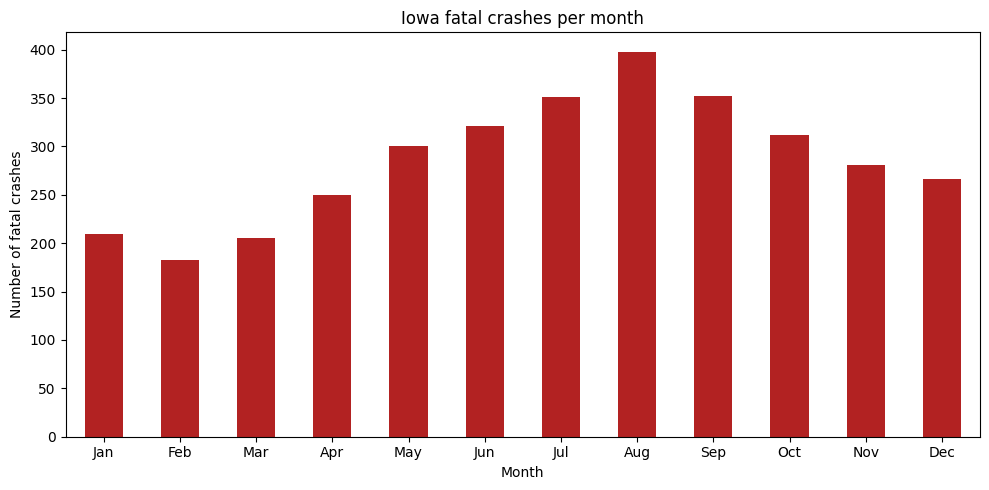

In [126]:
# all fatalities by month
import matplotlib.pyplot as plt

month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
per_month = df["MONTH"].value_counts().sort_index()

ax = per_month.plot(kind="bar", figsize=(10, 5), color="firebrick")
ax.set_xticklabels(month_names, rotation=0)
ax.set_xlabel("Month")
ax.set_ylabel("Number of fatal crashes")
ax.set_title("Iowa fatal crashes per month")
plt.tight_layout()
plt.show()


- Make sure each data point has a valid lat/long

In [128]:
df["LATITUDE"] = pd.to_numeric(df["LATITUDE"], errors="coerce")
df["LONGITUD"] = pd.to_numeric(df["LONGITUD"], errors="coerce")

# Rough bounding box around Iowa
valid = df["LATITUDE"].between(40.3, 43.6) & df["LONGITUD"].between(-96.7, -90.1)
print(f"Dropping {(~valid).sum()} crashes without a valid Iowa location")
print(len(df[valid]), "crashes total 2014 through 2024")

Dropping 2 crashes without a valid Iowa location
3426 crashes total 2014 through 2024


Draw on map using folium

In [ ]:
iowa_center = [42.0, -93.5]
m = folium.Map(location=iowa_center, zoom_start=6, tiles="OpenStreetMap")

for row in df.itertuples():
    folium.CircleMarker(
        location=[row.LATITUDE, row.LONGITUD],
        radius=3,
        color="red",
        weight=1,
        fill=True,
        fill_color="red",
        fill_opacity=0.6,
    ).add_to(m)

# CH add tooltip with number of fatalities

m

Fatal crashes by Years (2014 - 2024)

In [97]:
year_counts = df["YEAR"].value_counts().sort_index() # CH

print(year_counts)

YEAR
2014    288
2015    282
2016    355
2017    301
2018    291
2019    313
2020    310
2021    329
2022    305
2023    330
2024    324
Name: count, dtype: int64


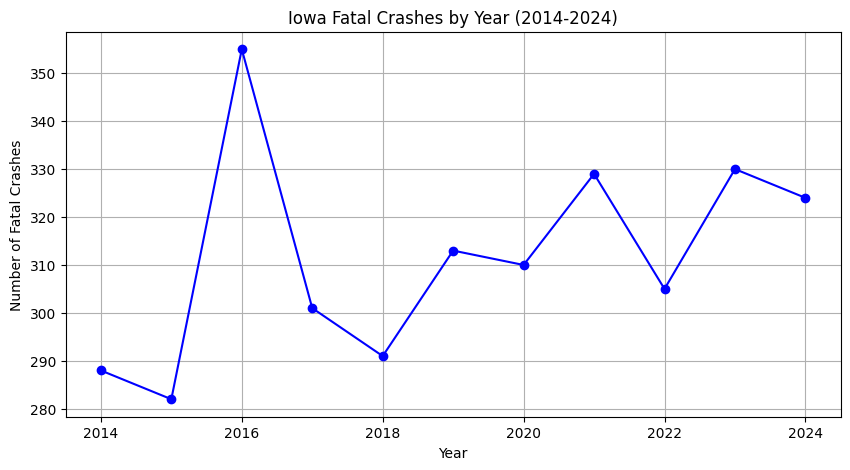

In [130]:
year_counts.plot(
    kind="line",
    marker="o",
    color="blue",
    figsize=(10,5),
    title="Iowa Fatal Crashes by Year (2014-2024)"
)

plt.xlabel("Year")
plt.ylabel("Number of Fatal Crashes")
plt.grid(True)

plt.show()

Crashes by Day of Week

In [99]:
print(df.columns.tolist())


['YEAR', 'STATE', 'ST_CASE', 'VE_TOTAL', 'VE_FORMS', 'PVH_INVL', 'PEDS', 'PERNOTMVIT', 'PERMVIT', 'PERSONS', 'COUNTY', 'CITY', 'DAY', 'MONTH', 'DAY_WEEK', 'HOUR', 'MINUTE', 'NHS', 'ROUTE', 'TWAY_ID', 'TWAY_ID2', 'MILEPT', 'LATITUDE', 'LONGITUD', 'SP_JUR', 'HARM_EV', 'MAN_COLL', 'RELJCT1', 'RELJCT2', 'TYP_INT', 'WRK_ZONE', 'REL_ROAD', 'LGT_COND', 'WEATHER', 'SCH_BUS', 'RAIL', 'NOT_HOUR', 'NOT_MIN', 'ARR_HOUR', 'ARR_MIN', 'HOSP_HR', 'HOSP_MN', 'FATALS', 'WEATHERNAME', 'INTERSECTION_TYPE', 'LIGHTNAME', 'MANNERNAME', 'DAY_WEEKNAME', 'COUNTYNAME']


In [131]:
[col for col in df.columns if "DAY" in col.upper()]

['DAY', 'DAY_WEEK', 'DAY_WEEKNAME']

In [101]:
day_counts = df["DAY_WEEKNAME"].value_counts()

print(day_counts)

DAY_WEEKNAME
Saturday     602
Friday       531
Sunday       510
Monday       492
Wednesday    438
Thursday     432
Tuesday      423
Name: count, dtype: int64


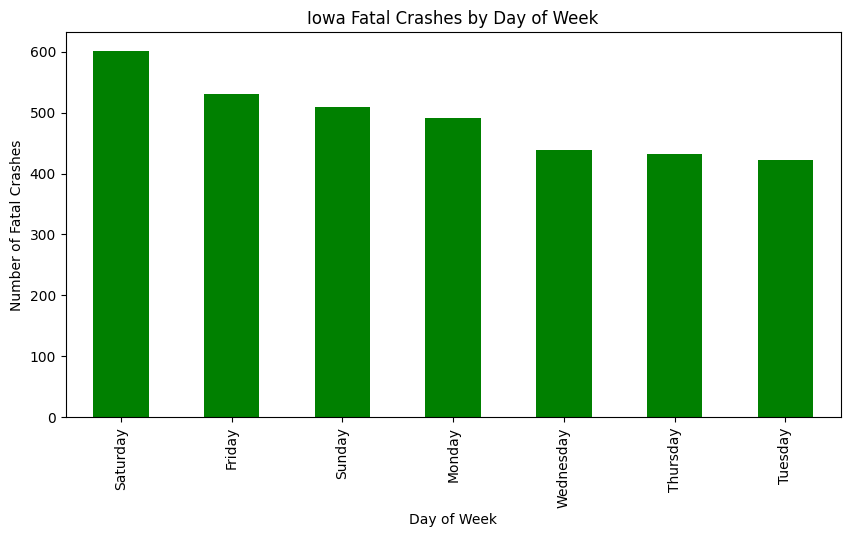

In [132]:
# CH this should be ordered by day of the week (starting Monday) and not by number of crashes!


import matplotlib.pyplot as plt

day_counts = df["DAY_WEEKNAME"].value_counts()

plt.figure(figsize=(10,5))

day_counts.plot(kind="bar", color="green")

plt.title("Iowa Fatal Crashes by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Number of Fatal Crashes")

plt.show()

Fatal Crashes by county 

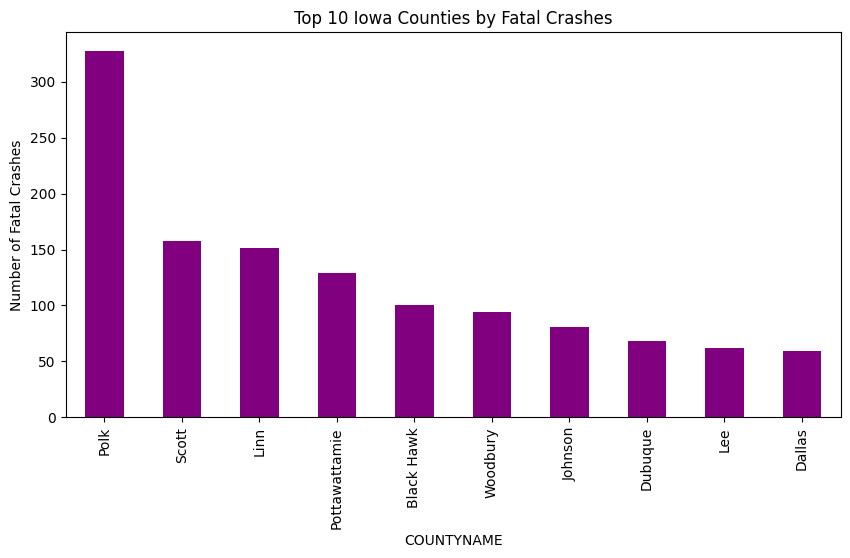

In [134]:
county_counts = df["COUNTYNAME"].value_counts().head(10)

county_counts.plot(
    kind="bar",
    figsize=(10,5),
    color="purple",
    title="Top 10 Iowa Counties by Fatal Crashes"
)

plt.ylabel("Number of Fatal Crashes")
plt.show()

At what time of day do fatal crashes occur most often?

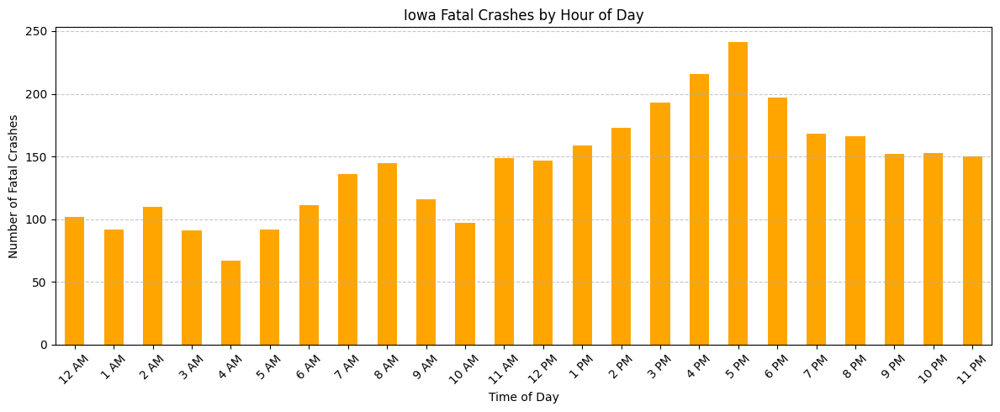

In [104]:
hour_labels = [
    "12 AM","1 AM","2 AM","3 AM","4 AM","5 AM",
    "6 AM","7 AM","8 AM","9 AM","10 AM","11 AM",
    "12 PM","1 PM","2 PM","3 PM","4 PM","5 PM",
    "6 PM","7 PM","8 PM","9 PM","10 PM","11 PM"
]

hour_counts = (
    df.loc[df["HOUR"] != 99, "HOUR"]  # 99 = unknown hour in FARS
    .value_counts()
    .reindex(range(24), fill_value=0)
    .sort_index()
)

hour_counts.plot(
    kind="bar",
    figsize=(12,5),
    color="orange",
    title="Iowa Fatal Crashes by Hour of Day"
)

plt.xticks(range(24), hour_labels, rotation=45)
plt.xlabel("Time of Day")
plt.ylabel("Number of Fatal Crashes")
plt.tight_layout()
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()

Day and Night crashes comparison map

In [ ]:
import folium

#df = pd.read_json("iowa_crashes/iowa_fars_2014_2024.json") don't do this, will loose all the new columns I added earlier

iowa_center = [42.0, -93.5]
m = folium.Map(location=iowa_center, zoom_start=7)

for row in df.itertuples():

    if 6 <= row.HOUR < 18:
        color = "orange"   # Day
    else:
        color = "blue"     # Night

    folium.CircleMarker(
        location=[row.LATITUDE, row.LONGITUD],
        radius=3,
        color=color,
        fill=True,
        fill_color=color
    ).add_to(m)

# CH add number of fatalities via tooltip

m

The number of crashes at each location

In [139]:
crash_counts = (
    df.groupby(["LATITUDE", "LONGITUD"])
      .size()
      .reset_index(name="Crash_Count")
)

m = folium.Map(location=[42.0, -93.5], zoom_start=7)

for _, row in crash_counts.iterrows():

    count = row["Crash_Count"]

    folium.CircleMarker(
        location=[row["LATITUDE"], row["LONGITUD"]],
        radius=count * count * 3,
        color="red",
        fill=True,
        fill_color="red",
        fill_opacity=0.6,
        popup=f"Crashes: {count}" # change to tooltip
    ).add_to(m)

m

Representing color-coded information for different number fatalities. Red being higher and green being lower

In [140]:
import pandas as pd
import folium

#df = pd.read_json("iowa_crashes/iowa_fars_2014_2024.json")

m = folium.Map(location=[42.0, -93.5], zoom_start=7)

for _, row in df.iterrows():

    if pd.notna(row["LATITUDE"]) and pd.notna(row["LONGITUD"]):

        fatalities = row["FATALS"]

        # Choose color
        if fatalities >= 3:
            color = "red"
        elif fatalities == 2:
            color = "orange"
        else:
            color = "green"

        folium.CircleMarker(
            location=[row["LATITUDE"], row["LONGITUD"]],
            radius=fatalities * 3,
            color=color,
            fill=True,
            fill_color=color,
            tooltip=f"Fatalities: {fatalities}"
        ).add_to(m)

m

Heat map to identify crash hotspots across the Iowa State. 

In [141]:
import pandas as pd
import numpy as np
import folium
from folium.plugins import HeatMap

#df = pd.read_json("iowa_crashes/iowa_fars_2014_2024.json")

df_map = df.dropna(subset=["LATITUDE", "LONGITUD"])

m = folium.Map(location=[42.0, -93.5], zoom_start=7)

heat_data = df_map[
    ["LATITUDE", "LONGITUD", "FATALS"]
].values.tolist()

HeatMap(
    heat_data,
    radius=12,
    blur=10
).add_to(m)

# Invisible markers on top of the heatmap provide the mouse-over text.
# The heat color comes from overlapping crashes, so the tooltip totals the
# fatalities (all years) within NEARBY_KM of each point.
NEARBY_KM = 1
lat = np.radians(df_map["LATITUDE"].to_numpy())
lon = np.radians(df_map["LONGITUD"].to_numpy())
x = lon * np.cos(lat) * 6371
y = lat * 6371
dist = np.hypot(x[:, None] - x[None, :], y[:, None] - y[None, :])
near = dist <= NEARBY_KM
fatals = df_map["FATALS"].to_numpy()
near_fatals = near @ fatals

for i, (_, row) in enumerate(df_map.iterrows()):
    folium.CircleMarker(
        location=[row["LATITUDE"], row["LONGITUD"]],
        radius=8,
        stroke=False,
        fill=True,
        fill_opacity=0,
        tooltip=f"Fatalities within {NEARBY_KM} km (all years): {near_fatals[i]}",
    ).add_to(m)

# Legend using the default Leaflet.heat gradient; the ends are the lowest and
# highest fatality totals within NEARBY_KM (the heat colors are scaled relative to the data)
legend_html = f"""
<div style="position: fixed; bottom: 0px; left: 0px; z-index: 9999;
            background: white; padding: 8px 12px; border: 1px solid #999;
            border-radius: 4px; font-size: 12px; color: #333;">
  <b>Fatalities within {NEARBY_KM} km</b>
  <div style="width: 160px; height: 12px; margin: 4px 0;
              background: linear-gradient(to right, blue 0%, cyan 40%, lime 60%, yellow 80%, red 100%);"></div>
  <div style="display: flex; justify-content: space-between;"><span>{near_fatals.min()}</span><span>{near_fatals.max()}</span></div>
</div>
"""
m.get_root().html.add_child(folium.Element(legend_html))

# Make the heat layer 50% transparent so the map shows through
m.get_root().header.add_child(folium.Element(
    "<style>.leaflet-heatmap-layer { opacity: 0.8; }</style>"
))

m

What weather conditations do fatal crashes happnes most ofthen in Iowa? Popup map. Green represent clear, blue represent rain, hot pink represent snow, purple represent fog and orange represent other. 

In [109]:
print(df.columns.tolist())

['YEAR', 'STATE', 'ST_CASE', 'VE_TOTAL', 'VE_FORMS', 'PVH_INVL', 'PEDS', 'PERNOTMVIT', 'PERMVIT', 'PERSONS', 'COUNTY', 'CITY', 'DAY', 'MONTH', 'DAY_WEEK', 'HOUR', 'MINUTE', 'NHS', 'ROUTE', 'TWAY_ID', 'TWAY_ID2', 'MILEPT', 'LATITUDE', 'LONGITUD', 'SP_JUR', 'HARM_EV', 'MAN_COLL', 'RELJCT1', 'RELJCT2', 'TYP_INT', 'WRK_ZONE', 'REL_ROAD', 'LGT_COND', 'WEATHER', 'SCH_BUS', 'RAIL', 'NOT_HOUR', 'NOT_MIN', 'ARR_HOUR', 'ARR_MIN', 'HOSP_HR', 'HOSP_MN', 'FATALS', 'WEATHERNAME', 'INTERSECTION_TYPE', 'LIGHTNAME', 'MANNERNAME', 'DAY_WEEKNAME', 'COUNTYNAME']


In [110]:
for col in df.columns:
    if "WEATHER" in col.upper():
        print(col)

WEATHER
WEATHERNAME


In [76]:
(
    df.groupby(["WEATHER", "WEATHERNAME"])
    .size()
    .reset_index(name="Frequency")
    .sort_values("Frequency", ascending=False)
    .reset_index(drop=True)
)


,WEATHER,WEATHERNAME,Frequency
0,1,Clear,2402
1,10,Cloudy,613
2,2,Rain,160
3,4,Snow,83
4,5,"Fog, Smog, Smoke",59
5,99,Reported as Unknown,41
6,12,Freezing Rain or Drizzle,30
7,6,Severe Crosswinds,15
8,11,Blowing Snow,9
9,8,Other,5


In [ ]:
import pandas as pd
import folium

#df = pd.read_json("iowa_crashes/iowa_fars_2014_2024.json")

m = folium.Map(location=[42.0, -93.5], zoom_start=7)

for _, row in df.iterrows():

    # CH change this to show the 5 most frequent weather types
    if pd.notna(row["LATITUDE"]) and pd.notna(row["LONGITUD"]):

        if row["WEATHER"] == 1:
            color = "green"
            weather = "Clear"

        elif row["WEATHER"] == 2:
            color = "blue"
            weather = "Rain"

        elif row["WEATHER"] == 4:
            color = "hot pink"
            weather = "Snow"

        elif row["WEATHER"] == 5:
            color = "purple"
            weather = "Fog"

        else:
            color = "orange"
            weather = "Other"

        folium.CircleMarker(
            location=[row["LATITUDE"], row["LONGITUD"]],
            radius=4,
            color=color,
            fill=True,
            fill_color=color,
            popup=f"Year: {row['YEAR']}<br>Weather: {weather}"
        ).add_to(m)

#m.save("weather_crash_map.html")

m

Crashes comparision for the Day and night (2014 - 2024). Popup map. Black represent night and green represent day.

In [112]:
import pandas as pd
import folium

# Load data
#df = pd.read_json("iowa_crashes/iowa_fars_2014_2024.json")

# Create map centered on Iowa
m = folium.Map(location=[42.0, -93.5], zoom_start=7)

# Add crash markers
for _, row in df.iterrows():

    # Skip missing coordinates
    if pd.notna(row["LATITUDE"]) and pd.notna(row["LONGITUD"]):

        # Day = Green
        if row["LGT_COND"] == 1:
            color = "green"
            light = "Day"

        # Night = Black
        else:
            color = "black"
            light = "Night"

        folium.CircleMarker(
            location=[row["LATITUDE"], row["LONGITUD"]],
            radius=4,
            color=color,
            fill=True,
            fill_color=color,
            popup=f"Year: {row['YEAR']}<br>{light}" #change to tooltip
        ).add_to(m)

m

Fatal Crashes by weather condition. Hover over map. Green markers represent clear weather conditions, blue markers represent rain, light gray markers represent snow, and orange markers represent cloudy conditions.

In [113]:
import pandas as pd
import folium

# Load data
#df = pd.read_json("iowa_crashes/iowa_fars_2014_2024.json")

# Create map centered on Iowa
m = folium.Map(location=[42.0, -93.5], zoom_start=7)

# Loop through crashes
for _, row in df.iterrows():

    # Skip rows with missing coordinates
    if pd.notna(row["LATITUDE"]) and pd.notna(row["LONGITUD"]):

        # Choose weather and color
        if row["WEATHER"] == 1:
            weather = "Clear"
            color = "green"

        elif row["WEATHER"] == 2:
            weather = "Rain"
            color = "blue"

        elif row["WEATHER"] == 4:
            weather = "Snow"
            color = "lightgray"

        elif row["WEATHER"] == 6:
            weather = "Cloudy"
            color = "orange"

        else:
            continue  # Skip other weather types

        # Add marker
        folium.CircleMarker(
            location=[row["LATITUDE"], row["LONGITUD"]],
            radius=5,
            color=color,
            fill=True,
            fill_color=color,

            # Information shown when hovering
            tooltip=
            f"Year: {row['YEAR']} | Weather: {weather}"

        ).add_to(m)

# Display map
m

Intersection vs Non-Intersection Crash Analysis (2014-2024). Hover over map. Red represent intersections and blue represent non-intersection. 

In [142]:
for col in df.columns:
    if "INT" in col.upper():
        print(col)

TYP_INT
INTERSECTION_TYPE


In [115]:
import pandas as pd
import folium

# Load data
#df = pd.read_json("iowa_crashes/iowa_fars_2014_2024.json")

# Create Iowa map
m = folium.Map(location=[42.0, -93.5], zoom_start=7)

for _, row in df.iterrows():

    if pd.notna(row["LATITUDE"]) and pd.notna(row["LONGITUD"]):

        # Example codes
        if row["TYP_INT"] == 1:
            location_type = "Intersection"
            color = "red"

        else:
            location_type = "Non-Intersection"
            color = "blue"

        folium.CircleMarker(
            location=[row["LATITUDE"], row["LONGITUD"]],
            radius=5,
            color=color,
            fill=True,
            fill_color=color,

            tooltip=
            f"Year: {row['YEAR']} | {location_type}"

        ).add_to(m)

m

Light condation accidnet hover over map. Green represent daylight, black represent dark(lighted), red represent dark(not lighted) and orange represent dawn. 

In [116]:
print(df["LGT_COND"].unique())

[1 2 3 4 5 6 9 8]


In [117]:
import pandas as pd
import folium

# Load data
#df = pd.read_json("iowa_crashes/iowa_fars_2014_2024.json")

# Create Iowa map
m = folium.Map(location=[42.0, -93.5], zoom_start=7)

# Add crash markers
for _, row in df.iterrows():

    if pd.notna(row["LATITUDE"]) and pd.notna(row["LONGITUD"]):

        # Light condition
        if row["LGT_COND"] == 1:
            light = "Daylight"
            color = "green"

        elif row["LGT_COND"] == 2:
            light = "Dark - Lighted"
            color = "black"

        elif row["LGT_COND"] == 3:
            light = "Dark - Not Lighted"
            color = "red"

        elif row["LGT_COND"] == 4:
            light = "Dawn"
            color = "orange"

        elif row["LGT_COND"] == 5:
            light = "Dusk"
            color = "purple"

        else:
            light = "Unknown"
            color = "gray"

        folium.CircleMarker(
            location=[row["LATITUDE"], row["LONGITUD"]],
            radius=5,
            color=color,
            fill=True,
            fill_color=color,

            tooltip=f"""
            Year: {row['YEAR']}
            <br>Light: {light}
            """

        ).add_to(m)

# Show map
m

Top 10 Iowa Counties by Fatal Crashes Hover Over Map.

In [119]:
county_columns = [col for col in df.columns if "COUNTY" in col.upper()]
print(county_columns)


['COUNTY', 'COUNTYNAME']


In [120]:
import pandas as pd

#df = pd.read_json("iowa_crashes/iowa_fars_2014_2024.json")

top_counties = df["COUNTYNAME"].value_counts().head(10)

print(top_counties)

COUNTYNAME
Polk             328
Scott            158
Linn             151
Pottawattamie    129
Black Hawk       100
Woodbury          94
Johnson           81
Dubuque           68
Lee               62
Dallas            59
Name: count, dtype: int64


In [121]:
import pandas as pd
import folium

# Load data
#df = pd.read_json("iowa_crashes/iowa_fars_2014_2024.json")

county_names = {
    13: "Black Hawk",
    49: "Dallas",
    61: "Dubuque",
    103: "Johnson",
    111: "Lee",
    113: "Linn",
    153: "Polk",
    155: "Pottawattamie",
    163: "Scott",
    193: "Woodbury"
}

# Count crashes by county code
county_counts = df["COUNTY"].value_counts()

top_counties = list(county_names.keys())

top_df = df[df["COUNTY"].isin(top_counties)]

m = folium.Map(location=[42.0, -93.5], zoom_start=7)

for _, row in top_df.iterrows():

    if pd.notna(row["LATITUDE"]) and pd.notna(row["LONGITUD"]):

        county_name = county_names.get(row["COUNTY"], "Unknown")

        crash_count = county_counts[row["COUNTY"]]

        folium.CircleMarker(
            location=[row["LATITUDE"], row["LONGITUD"]],
            radius=5,
            color="red",
            fill=True,
            fill_color="red",

            tooltip=f"""
            County: {county_name}
            <br>Total Fatal Crashes: {crash_count}
            <br>Year: {row['YEAR']}
            """

        ).add_to(m)

m

### Collision Type Color Popup Map. 
Red markers represent head-on collisions, orange markers represent angle collisions, blue markers represent front-to-rear collisions, and green markers represent single-vehicle or fixed-object crashes.

In [122]:
import pandas as pd

#df = pd.read_json("iowa_crashes/iowa_fars_2014_2024.json")

print(df.head())
print(df.columns.tolist())

   YEAR  STATE  ST_CASE  VE_TOTAL  VE_FORMS  PVH_INVL  PEDS  PERNOTMVIT  \
0  2014     19   190001         1         1         0     0           0   
1  2014     19   190002         2         2         0     0           0   
2  2014     19   190003         2         2         0     0           0   
3  2014     19   190004         2         2         0     0           0   
4  2014     19   190005         1         1         0     0           0   

   PERMVIT  PERSONS  ...  ARR_MIN  HOSP_HR  HOSP_MN  FATALS  \
0        1        1  ...       48       15        8       1   
1        6        6  ...        0       99       99       4   
2        2        2  ...       43       17       54       1   
3        3        3  ...       22       99       99       1   
4        1        1  ...       35       20       33       1   

                WEATHERNAME    INTERSECTION_TYPE           LIGHTNAME  \
0                     Clear  Not an intersection            Daylight   
1  Freezing Rain or Drizzl

In [ ]:
import pandas as pd
import folium

# New map so this cell doesn't reuse the heatmap and its tooltips from an earlier cell
m = folium.Map(location=[42.0, -93.5], zoom_start=7)

# CH translate collision type into text:
collision_types = {
    0: "Not a collision with a motor vehicle in transport",
    1: "Front-to-Rear",
    2: "Head-On",  # FARS calls this Front-to-Front
    6: "Angle",
    7: "Sideswipe Same Direction",
    8: "Sideswipe Opposite Direction",
    9: "Rear-to-Side",
}

df["Collision_Type"] = df["MAN_COLL"].map(collision_types).fillna("Other / Unknown")


# Loop through each crash record
for _, row in df.iterrows():

    # Make sure coordinates exist
    if pd.notna(row["LATITUDE"]) and pd.notna(row["LONGITUD"]):

        collision = row["Collision_Type"]

        # Assign colors using if-elif-else
        if collision == "Head-On":
            color = "red"

        elif collision == "Angle":
            color = "orange"

        elif collision == "Front-to-Rear":
            color = "blue"

        elif collision == "Sideswipe Same Direction":
            color = "purple"

        elif collision == "Sideswipe Opposite Direction":
            color = "pink"

        elif collision == "Rear-to-Side":
            color = "black"

        else:
            color = "green"  # Single Vehicle, Other, Unknown

        # Add marker to map
        folium.CircleMarker(
            location=[row["LATITUDE"], row["LONGITUD"]],
            radius=5,
            color=color,
            fill=True,
            fill_color=color,
            fill_opacity=0.7,
            tooltip=f"Fatalities: {row['FATALS']}",
            popup=f"""
            <b>Year:</b> {row['YEAR']}<br>
            <b>Collision Type:</b> {collision}<br>
            <b>Fatalities:</b> {row['FATALS']}
            """
        ).add_to(m)

# HTML legend (labels and colors match the if-elif chain above)
legend_items = [
    ("Head-On", "red"),
    ("Angle", "orange"),
    ("Front-to-Rear", "blue"),
    ("Sideswipe Same Direction", "purple"),
    ("Sideswipe Opposite Direction", "pink"),
    ("Rear-to-Side", "black"),
    ("Other / Single Vehicle / Unknown", "green"),
]

legend_rows = "".join(
    f'<div style="margin-bottom:4px;">'
    f'<span style="display:inline-block;width:12px;height:12px;border-radius:50%;'
    f'background:{c};margin-right:8px;vertical-align:middle;"></span>{label}</div>'
    for label, c in legend_items
)

legend_html = f"""
<div style="position: fixed; bottom: 5; left: 5; z-index: 9999;
            background: white; padding: 10; border: 2px solid grey;
            font-size: 10px; box-shadow: 2px 2px 6px rgba(0,0,0,0.3);">
    <b>Collision Type</b><br>
    {legend_rows}
</div>
"""

m.get_root().html.add_child(folium.Element(legend_html))

# Show map
m
